# 01 — Exploratory data analysis

**Data:** dunnhumby *Breakfast at the Frat* — weekly sales, prices and promotions for the top products of 4 categories (cold cereal, frozen pizza, pretzels, mouthwash), 77 stores in 4 US states, 156 weeks (Jan 2009 – Jan 2012).

**Questions for this notebook**
1. Is the data clean enough to model prices and promotions?
2. How often are products promoted, and with which mechanic?
3. How much do sales move during a promotion, and does it depend on the mechanic and the category?
4. Does deeper discount mean more volume?

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

con = duckdb.connect("../data/frat.duckdb", read_only=True)
sql = lambda q: con.sql(q).df()

# Chart style: thin marks, recessive axes, fixed categorical order
CAT_ORDER = ["COLD CEREAL", "FROZEN PIZZA", "BAG SNACKS", "ORAL HYGIENE PRODUCTS"]
CAT_LABEL = {"COLD CEREAL": "Cold cereal", "FROZEN PIZZA": "Frozen pizza",
             "BAG SNACKS": "Pretzels", "ORAL HYGIENE PRODUCTS": "Mouthwash"}
CAT_COLOR = dict(zip(CAT_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 11,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "legend.frameon": False,
})
FIG = "../reports/figures/"


## 1. Data quality
All checks are in `sql/02_quality_checks.sql`; decisions are logged in `docs/data_quality_log.md`.

In [2]:
sql("""
SELECT MIN(WEEK_END_DATE)::DATE AS first_week, MAX(WEEK_END_DATE)::DATE AS last_week,
       COUNT(DISTINCT WEEK_END_DATE) AS weeks, COUNT(DISTINCT STORE_NUM) AS stores,
       COUNT(DISTINCT UPC) AS products, COUNT(*) AS rows
FROM raw_transactions""")

,first_week,last_week,weeks,stores,products,rows
0,2009-01-14,2012-01-04,156,77,55,524950


In [3]:
sql("""
SELECT SUM((PRICE IS NULL OR PRICE <= 0)::INT)  AS bad_price,
       SUM((BASE_PRICE IS NULL)::INT)            AS missing_base_price,
       SUM((UNITS <= 0)::INT)                    AS non_positive_units,
       SUM((PRICE > BASE_PRICE * 1.05)::INT)     AS price_above_base,
       SUM((VISITS > UNITS)::INT)                AS more_baskets_than_units,
       COUNT(*) - (SELECT COUNT(*) FROM sales)   AS rows_excluded
FROM raw_transactions""")

,bad_price,missing_base_price,non_positive_units,price_above_base,more_baskets_than_units,rows_excluded
0,24.0,185.0,5.0,2066.0,2309.0,209


**Findings**
- No duplicate keys and no orphan store or product: joins are safe.
- 209 rows (0.04 %) have a missing or non-positive price or units → excluded from `sales`.
- 2,066 rows have a shelf price more than 5 % **above** the base price, and 2,309 rows show more baskets than units, which is impossible. These are kept for now but flagged; their impact will be tested in the models.
- Only 1,225 of 3,909 store × product series cover all 156 weeks (median 149). Products are not sold every week in every store, so models must handle gaps.
- 55 of the 58 listed products and 77 of the 79 listed stores actually appear in the sales.

## 2. What the portfolio looks like

In [4]:
sql("""
SELECT p.category,
       COUNT(DISTINCT s.upc)                         AS products,
       ROUND(SUM(s.spend) / 1e6, 2)                  AS sales_musd,
       ROUND(AVG(s.price), 2)                        AS avg_price_usd,
       ROUND(100 * AVG((s.mechanic <> 'No promo')::INT), 1) AS pct_weeks_on_promo,
       ROUND(100 * AVG(s.discount_depth) FILTER (WHERE s.discount_depth > 0.02), 1) AS avg_discount_when_reduced_pct
FROM sales s JOIN products p USING (upc)
GROUP BY 1 ORDER BY sales_musd DESC""")

,category,products,sales_musd,avg_price_usd,pct_weeks_on_promo,avg_discount_when_reduced_pct
0,COLD CEREAL,15,15.01,2.74,23.7,22.1
1,FROZEN PIZZA,12,6.45,5.31,30.6,23.5
2,BAG SNACKS,15,4.73,2.20,30.4,19.6
3,ORAL HYGIENE PRODUCTS,13,1.73,3.77,31.2,26.1


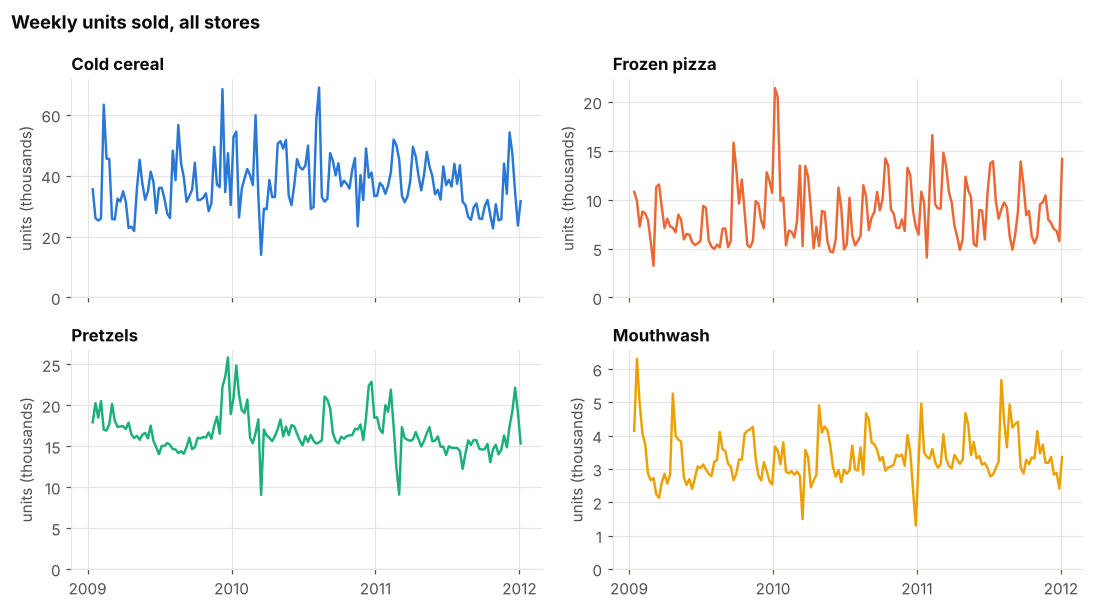

In [5]:
wk = sql("""
SELECT s.week, p.category, SUM(s.units) AS units
FROM sales s JOIN products p USING (upc)
GROUP BY ALL ORDER BY week""")
fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharex=True)
for ax, cat in zip(axes.flat, CAT_ORDER):
    d = wk[wk.category == cat]
    ax.plot(d.week, d.units / 1000, color=CAT_COLOR[cat], lw=1.6)
    ax.set_title(CAT_LABEL[cat])
    ax.set_ylim(bottom=0)
    ax.set_ylabel("units (thousands)")
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Weekly units sold, all stores", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(FIG + "01_weekly_units.png", bbox_inches="tight")

Weekly volume is spiky rather than smooth: peaks of up to 2–3× the usual level line up with promotion weeks. Pretzels show a winter peak each year (December–February), the only clear seasonality. A few isolated dips (cereal in spring 2010, pretzels in 2010 and 2011) are not explained by missing stores — every week has 76–77 stores — and will be checked against prices in notebook 02. Cereal is by far the largest category in volume.

## 3. Promotion mechanics and their raw lift
Lift = units in a week ÷ the average units of the same product in the same store during weeks **without** any promotion.

In [6]:
lift = sql("""
WITH base AS (
    SELECT store_id, upc, AVG(units) AS base_units
    FROM sales WHERE mechanic = 'No promo' GROUP BY ALL
)
SELECT p.category, s.mechanic, COUNT(*) AS weeks,
       ROUND(100 * AVG(s.discount_depth), 1) AS avg_discount_pct,
       ROUND(AVG(s.units / b.base_units), 2) AS raw_lift
FROM sales s JOIN base b USING (store_id, upc) JOIN products p USING (upc)
WHERE s.mechanic <> 'No promo'
GROUP BY ALL""")
lift.pivot(index="mechanic", columns="category", values="raw_lift").loc[
    ["Feature + Display", "Feature", "Display", "TPR only"], CAT_ORDER]

category,COLD CEREAL,FROZEN PIZZA,BAG SNACKS,ORAL HYGIENE PRODUCTS
mechanic,,,,
Feature + Display,5.00,4.13,3.19,3.26
Feature,3.20,2.99,1.95,2.54
Display,2.84,2.69,1.61,1.67
TPR only,1.34,1.64,1.18,1.46


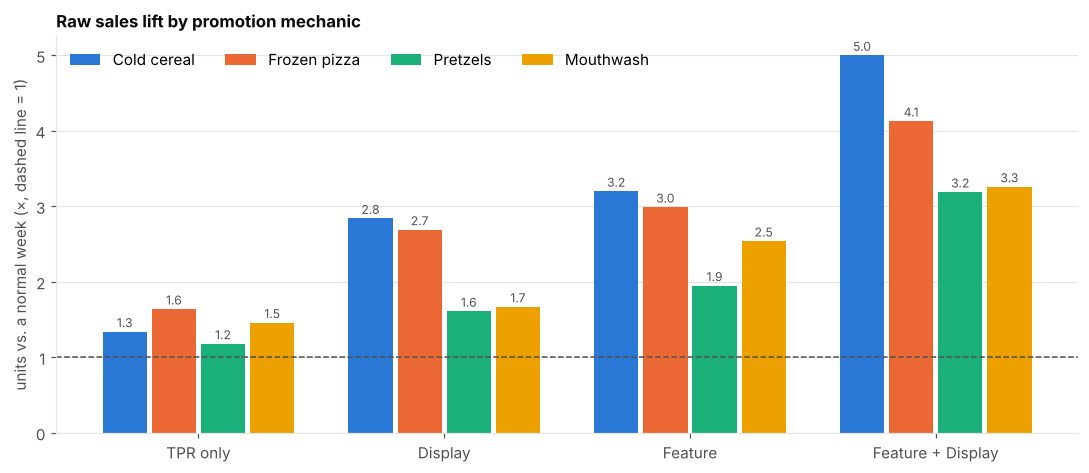

In [7]:
mechs = ["TPR only", "Display", "Feature", "Feature + Display"]
x = np.arange(len(mechs)); w = 0.2
fig, ax = plt.subplots(figsize=(10, 4.4))
for i, cat in enumerate(CAT_ORDER):
    v = lift[lift.category == cat].set_index("mechanic").loc[mechs, "raw_lift"]
    bars = ax.bar(x + (i - 1.5) * w, v, w * 0.9, color=CAT_COLOR[cat], label=CAT_LABEL[cat])
    for b, val in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, val + 0.06, f"{val:.1f}", ha="center", fontsize=8, color=INK2)
ax.axhline(1, color=INK2, lw=1, ls="--")
ax.set_xticks(x, mechs)
ax.set_ylabel("units vs. a normal week (×, dashed line = 1)")
ax.set_title("Raw sales lift by promotion mechanic")
ax.legend(ncol=4, loc="upper left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG + "02_raw_lift_by_mechanic.png", bbox_inches="tight")

**Findings**
- The ranking is the same in every category: price cut only < display < feature < feature + display.
- Combining feature (circular) and display multiplies sales by **3 to 5**; a price cut alone with only a shelf tag adds 20–60 %.
- Cereal and pizza react most strongly to in-store and circular support.

⚠️ **This raw lift mixes two effects**: the price cut and the marketing support. Feature + display weeks also carry the deepest discounts (≈25 %). Separating the two is the job of the elasticity model (notebook 02).

## 4. Does a deeper discount sell more?

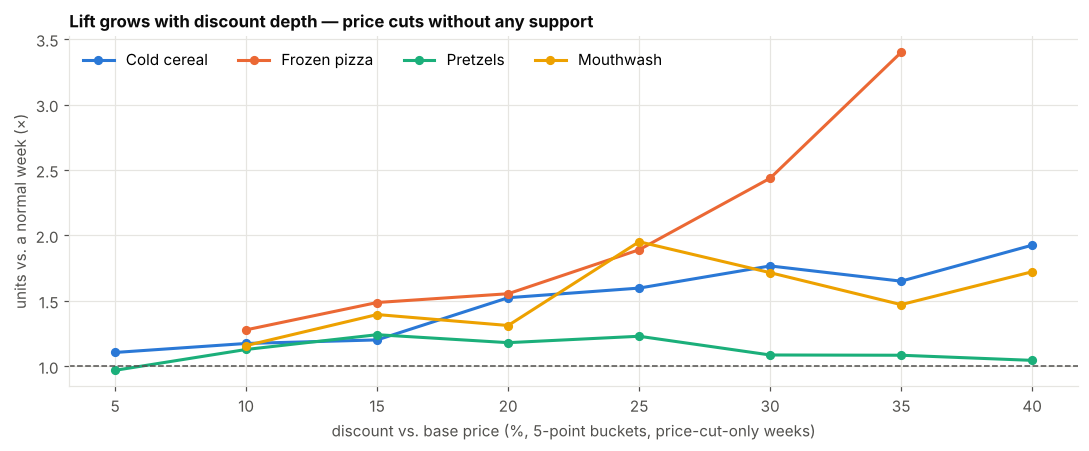

In [8]:
dd = sql("""
WITH base AS (
    SELECT store_id, upc, AVG(units) AS base_units
    FROM sales WHERE mechanic = 'No promo' GROUP BY ALL
)
SELECT p.category,
       LEAST(FLOOR(s.discount_depth * 20) * 5, 40) AS discount_bucket_pct,
       COUNT(*) AS weeks,
       AVG(s.units / b.base_units) AS raw_lift
FROM sales s JOIN base b USING (store_id, upc) JOIN products p USING (upc)
WHERE s.mechanic = 'TPR only' AND s.discount_depth >= 0
GROUP BY ALL HAVING COUNT(*) >= 100 ORDER BY 1, 2""")
fig, ax = plt.subplots(figsize=(10, 4.2))
for cat in CAT_ORDER:
    d = dd[dd.category == cat]
    ax.plot(d.discount_bucket_pct, d.raw_lift, color=CAT_COLOR[cat], lw=2, marker="o", ms=5, label=CAT_LABEL[cat])
ax.axhline(1, color=INK2, lw=1, ls="--")
ax.set_xlabel("discount vs. base price (%, 5-point buckets, price-cut-only weeks)")
ax.set_ylabel("units vs. a normal week (×)")
ax.set_title("Lift grows with discount depth — price cuts without any support")
ax.legend(ncol=4, loc="upper left")
fig.tight_layout()
fig.savefig(FIG + "03_lift_vs_discount.png", bbox_inches="tight")

Looking only at price-cut weeks without feature or display isolates the price effect. The categories behave very differently: frozen pizza volume climbs steeply (×3.4 at a 35 % discount), cereal and mouthwash rise moderately and level off, and pretzels barely react whatever the discount. A deep price cut on pretzels without support mostly gives margin away. Buckets with fewer than 100 weeks are hidden.

## 5. Preliminary price elasticity (sanity check)
Log-log regression of units on shelf price, within each store × product series (fixed effects), controlling for feature and display. A proper model with week effects and cross-elasticities comes in notebook 02.

In [9]:
import statsmodels.formula.api as smf

d = sql("SELECT s.*, p.category FROM sales s JOIN products p USING (upc)")
d["log_units"], d["log_price"] = np.log(d.units), np.log(d.price)
d["series"] = d.store_id.astype(str) + "_" + d.upc.astype(str)
rows = []
for cat, g in d.groupby("category"):
    g = g.copy()
    for v in ["log_units", "log_price", "feature", "display"]:
        g[v + "_w"] = g[v] - g.groupby("series")[v].transform("mean")   # within transformation
    m = smf.ols("log_units_w ~ log_price_w + feature_w + display_w - 1", g).fit(
        cov_type="cluster", cov_kwds={"groups": g["series"].astype("category").cat.codes})
    rows.append({"category": CAT_LABEL[cat],
                 "price_elasticity": m.params["log_price_w"],
                 "ci_low": m.conf_int().loc["log_price_w", 0], "ci_high": m.conf_int().loc["log_price_w", 1],
                 "feature_multiplier": np.exp(m.params["feature_w"]),
                 "display_multiplier": np.exp(m.params["display_w"])})
pd.DataFrame(rows).round(2).sort_values("price_elasticity")

,category,price_elasticity,ci_low,ci_high,feature_multiplier,display_multiplier
2,Frozen pizza,-2.75,-2.93,-2.57,1.31,1.51
1,Cold cereal,-1.59,-1.67,-1.52,1.61,1.73
3,Mouthwash,-1.25,-1.30,-1.20,1.61,1.28
0,Pretzels,-1.24,-1.33,-1.15,1.47,1.46


**Reading:** an elasticity of −2.7 for frozen pizza means a 10 % price cut raises volume by about 30 %. All categories are elastic (below −1), so a price cut increases units *more* than proportionally — but that does not mean it is profitable, since margin per unit falls.

Once the price effect is removed, feature and display still add **30 % to 70 %** on their own: the marketing support has value beyond the discount.

## Next steps
- Notebook 02: elasticity per product with week fixed effects (to absorb seasonality and demand shocks) and cross-price elasticities between brands.
- Test the sensitivity of the results to the ~4,400 flagged rows (price above base, more baskets than units).
- Notebook 03: baseline vs incremental volume, and the post-promotion dip.